# 영업 메일 워크플로 — LangGraph 버전

`openai_agent_code.ipynb`, `langchain_agent_code.ipynb`와 **같은 시나리오**를
이번에는 **그래프**로 만듭니다.

## 시나리오 (동일)

**주식회사 윈스테크넷**의 **스나이퍼 APT**를 파는 Sales Group.
판매원 세 명(정직 / 유머 / 공격)이 초안을 쓰고, 하나를 골라 보냅니다.

## 왜 그래프가 필요한가 — LangChain의 한계

LangChain의 `|`는 **일직선**입니다.

```
A | B | C        앞으로만 간다
```

그런데 실무의 흐름은 대개 이렇습니다.

```
초안 -> 검수 -> 통과? -> 발송
          ^        |
          +--아니오-+   다시 쓴다
```

**되돌아가는 화살표**가 있습니다. `|`로는 이것을 표현할 수 없습니다.
`if`와 `while`로 감쌀 수는 있지만, 그러면 체인이 아니라 그냥 파이썬 코드가 됩니다.
상태 관리, 중간 저장, 단계별 관찰을 전부 직접 해야 합니다.

**LangGraph는 이 고리(cycle)를 일급 기능으로 다룹니다.**

| | LangChain | LangGraph |
|---|---|---|
| 구조 | 일직선 파이프 | **그래프** (노드 + 엣지) |
| 갈라지기 | 어려움 | `add_conditional_edges` |
| 되돌아가기 | **불가** | 엣지 하나 추가하면 됨 |
| 중간 상태 | 직접 관리 | **State**가 들고 다님 |
| 중단/재개 | 없음 | 체크포인터 |

> **실행 순서**: 위에서부터 차례대로 실행하세요. `agent/` 폴더에서 실행하는 것을 전제로 합니다.

## Step 0. 준비

LangGraph는 LangChain 위에 얹혀 있습니다. 모델과 프롬프트는 LangChain 것을 그대로 씁니다.
LangGraph가 더하는 것은 **흐름을 짜는 방법**뿐입니다.

In [5]:
import operator
import os
import smtplib
from email.message import EmailMessage
from typing import Annotated, Literal, TypedDict

from dotenv import load_dotenv
from IPython.display import Image, display
from langchain_openai import ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver

load_dotenv(override=True)

MODEL_NAME = "gpt-5.4-mini"
llm = ChatOpenAI(model=MODEL_NAME)
parser = StrOutputParser()

print("모델:", MODEL_NAME)
print("LangSmith 추적:", os.getenv("LANGSMITH_TRACING"))

모델: gpt-5.4-mini
LangSmith 추적: true


## Step 1. 메일 보내기 준비 (안전장치 포함)

앞의 두 노트북과 같습니다. 프레임워크와 무관한 부분입니다.

In [6]:
EMAIL_ADDRESS = os.getenv("EMAIL_ADDRESS")
EMAIL_SMTP_SERVER = os.getenv("EMAIL_SMTP_SERVER")
EMAIL_APP_PASSWORD = os.getenv("EMAIL_APP_PASSWORD")

SEND_FOR_REAL = False   # True로 바꾸면 진짜 메일이 나갑니다

HAS_EMAIL_CONFIG = all([EMAIL_ADDRESS, EMAIL_SMTP_SERVER, EMAIL_APP_PASSWORD])


def send_email(subject, text_body):
    msg = EmailMessage()
    msg["From"] = EMAIL_ADDRESS
    msg["To"] = EMAIL_ADDRESS
    msg["Subject"] = subject
    msg.set_content(text_body)
    with smtplib.SMTP(EMAIL_SMTP_SERVER, 587) as server:
        server.starttls()
        server.login(EMAIL_ADDRESS, EMAIL_APP_PASSWORD)
        server.send_message(msg)


def send_message(subject, text_body):
    if SEND_FOR_REAL and HAS_EMAIL_CONFIG:
        send_email(subject, text_body)
        return "메일을 실제로 보냈습니다."
    print("=" * 66)
    print("[미리보기] 실제로 보내지 않았습니다")
    print("제목:", subject)
    print("-" * 66)
    print(text_body[:400])
    print("=" * 66)
    return "미리보기로 출력했습니다."


print("발송 모드:", "실제 발송" if SEND_FOR_REAL else "미리보기 (화면 출력만)")

발송 모드: 미리보기 (화면 출력만)


## Step 2. 상태(State) — LangGraph의 중심

그래프에서 노드들은 **하나의 상태를 함께 고쳐 나갑니다.**
상태는 `TypedDict`로 "어떤 칸이 있는지" 선언합니다.

```python
class State(TypedDict):
    drafts: Annotated[list[str], operator.add]
    selected: str
```

### `Annotated[..., operator.add]`가 무엇인가

**리듀서(reducer)** 입니다. **여러 노드가 같은 칸에 동시에 쓸 때 어떻게 합칠지**를 정합니다.

판매원 세 명이 **동시에** `drafts`에 쓰기 때문에 이것이 꼭 필요합니다.
`operator.add`는 리스트끼리 `+`를 하므로 세 초안이 **이어 붙습니다.**

리듀서가 없으면 어떻게 될까요? 말로 설명하는 대신 직접 오류를 내 봅니다.

In [12]:
class BadState(TypedDict):
    x: str          # 리듀서 없음


bad = StateGraph(BadState)
bad.add_node("a", lambda s: {"x": "A가 씀"})
bad.add_node("b", lambda s: {"x": "B가 씀"})
bad.add_edge(START, "a")
bad.add_edge(START, "b")       # a와 b가 동시에 실행된다
bad.add_edge("a", END)
bad.add_edge("b", END)

try:
    bad.compile().invoke({"x": ""})
except Exception as error:
    print(type(error).__name__)
    print(str(error).split("For troubleshooting")[0].strip())

InvalidUpdateError
At key 'x': Can receive only one value per step. Use an Annotated key to handle multiple values.


> `Can receive only one value per step. Use an Annotated key to handle multiple values.`
>
> **두 노드가 같은 칸에 동시에 쓰면 LangGraph는 조용히 하나를 고르지 않고 멈춥니다.**
> 이것이 좋은 설계입니다. 조용히 덮어썼다면 판매원 한 명의 초안만 남고
> 나머지 둘은 사라지는데, 결과만 봐서는 알아차리기 어렵습니다.
>
> 리듀서를 붙이면 해결됩니다.

In [9]:
class GoodState(TypedDict):
    x: Annotated[list, operator.add]     # 리스트로 모은다


good = StateGraph(GoodState)
good.add_node("a", lambda s: {"x": ["A가 씀"]})
good.add_node("b", lambda s: {"x": ["B가 씀"]})
good.add_edge(START, "a")
good.add_edge(START, "b")
good.add_edge("a", END)
good.add_edge("b", END)
build = good.compile()
#print(good.compile().invoke({"x": []}))

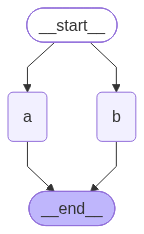

In [10]:
display(Image(build.get_graph().draw_mermaid_png()))

In [11]:
print(build.invoke({"x": []}))

{'x': ['A가 씀', 'B가 씀']}


### 이번 워크플로의 상태

| 칸 | 담는 것 | 리듀서 |
|---|---|---|
| `request` | 사용자의 요청 | 없음 (안 바뀜) |
| `drafts` | 초안들 | **`operator.add`** (셋이 동시에 씀) |
| `selected` | 고른 메일 | 없음 (한 노드만 씀) |
| `issues` | 검수에서 걸린 표현 | 없음 |
| `revisions` | 재작성 횟수 | 없음 |
| `sent` | 발송 결과 | 없음 |

**리듀서는 동시에 쓰는 칸에만 필요합니다.** 한 노드만 쓰는 칸에는 없어도 됩니다.

In [13]:
class State(TypedDict):
    request: str
    drafts: Annotated[list[str], operator.add]
    selected: str
    issues: list[str]
    revisions: int
    sent: str


def new_state(request: str) -> State:
    """초기 상태를 만든다. 모든 칸을 채워 두면 노드에서 KeyError가 나지 않는다."""
    return {"request": request, "drafts": [], "selected": "",
            "issues": [], "revisions": 0, "sent": ""}


print(new_state("영업 메일 초안을 하나 써 주세요"))

{'request': '영업 메일 초안을 하나 써 주세요', 'drafts': [], 'selected': '', 'issues': [], 'revisions': 0, 'sent': ''}


## Step 3. 노드 = 판매원

**노드는 그냥 함수입니다.**

```python
def 노드(state) -> dict:
    return {"고칠_칸": 새값}
```

규칙은 두 가지뿐입니다.

1. 상태를 받는다
2. **바꿀 칸만** 담은 딕셔너리를 돌려준다 (전체 상태를 돌려줄 필요 없음)

`Agent` 객체도, `Runnable`도 아닙니다. 그래서 테스트하기 쉽습니다.
딕셔너리 하나 만들어 넣고 결과를 보면 됩니다.

In [14]:
intro = """당신은 주식회사 윈스테크넷의 영업 담당자입니다.
'스나이퍼 APT'라는 지능형 지속 위협(APT) 대응 솔루션을 판매합니다.
이 제품은 알려지지 않은 악성코드와 표적 공격을 네트워크 단에서 탐지하고 차단합니다.
당신의 일은 잠재 고객에게 보낼 영업 메일을 쓰는 것입니다.
메일은 한국어로 쓰고, 첫 줄에 '제목:'을 적으세요.
"""

STYLES = {
    "honest": ("판매원1 (정직)", """당신의 메일 스타일은 매우 정직합니다.
과장하거나 부풀리지 않습니다. 확인된 사실만 씁니다.
제품이 해결하지 못하는 부분이 있다면 그것도 솔직하게 밝힙니다."""),
    "humorous": ("판매원2 (유머)", """당신의 메일 스타일은 유머러스합니다.
가볍고 재치 있는 표현으로 읽는 사람의 부담을 덜어줍니다.
다만 제품 정보 자체는 정확하게 전달합니다."""),
    "aggressive": ("판매원3 (공격)", """당신의 메일 스타일은 매우 공격적입니다.
이 제품을 도입하지 않으면 고객사가 큰 피해를 입고 사업이 무너질 수 있다는 점을 강하게 압박합니다.
위기감을 최대한 강조하고 즉시 결정할 것을 요구합니다."""),
}

write_prompt = ChatPromptTemplate.from_messages([
    ("system", intro + "\n{style}"),
    ("human", "{request}"),
])

### 노드 세 개를 한 번에 만들기

세 판매원은 성향만 다르므로 **함수를 만들어 내는 함수**로 찍어 냅니다.
같은 코드를 세 번 복사하면 한 곳만 고쳤을 때 티가 안 납니다.

초안 앞에 `[판매원N]` 표를 붙이는 이유: `drafts` 리스트에 세 개가 섞여 들어가므로,
나중에 **누가 쓴 것인지 알아볼 수 있어야** 합니다.

In [15]:
def make_writer(key):
    """성향 하나에 해당하는 노드 함수를 만든다."""
    label, style = STYLES[key]

    def node(state: State) -> dict:
        chain = write_prompt | llm | parser
        text = chain.invoke({"style": style, "request": state["request"]})
        return {"drafts": [f"[{label}]\n{text}"]}

    node.__name__ = key
    return node


# 노드 하나를 따로 테스트해 본다. 그래프 없이도 된다.
sample = make_writer("honest")(new_state("한 문단짜리 짧은 영업 메일을 써 주세요"))
print(sample["drafts"][0][:300])

[판매원1 (정직)]
제목: 네트워크 단에서 알려지지 않은 위협 탐지·차단을 지원하는 스나이퍼 APT 안내드립니다

안녕하세요, 주식회사 윈스테크넷입니다. 당사의 ‘스나이퍼 APT’는 네트워크 단에서 알려지지 않은 악성코드와 표적 공격을 탐지하고 차단하는 지능형 지속 위협(APT) 대응 솔루션입니다. 다만 모든 공격을 100% 막을 수 있는 것은 아니며, 최종적인 보안 운영과 정책 적용은 고객 환경에 맞는 추가 설정과 연계가 필요합니다. 필요하시면 짧게 제품 소개와 적용 방식에 대해 안내드리겠습니다.


## Step 4. 그래프 조립 — 팬아웃과 조인

이제 노드를 엣지로 잇습니다.

```python
graph.add_node("이름", 함수)       # 노드 등록
graph.add_edge("A", "B")          # A 다음에 B
```

`START`와 `END`는 미리 정해진 특별한 지점입니다.

### 병렬은 "엣지를 여러 개 긋는 것"

```python
graph.add_edge(START, "honest")
graph.add_edge(START, "humorous")     # 셋 다 START에서 출발
graph.add_edge(START, "aggressive")
```

`asyncio.gather`도 `RunnableParallel`도 필요 없습니다.
**START에서 나가는 화살표가 셋이면 셋이 동시에 실행됩니다.**
LangGraph가 의존 관계를 보고 알아서 병렬로 돌립니다.

그리고 셋 모두 `select`로 들어가는 엣지를 그으면,
`select`는 **셋이 다 끝날 때까지 기다립니다.** 이것이 조인입니다.

In [16]:
def select_node(state: State) -> dict:
    """초안 중 하나를 고른다."""
    joined = "\n\n---다음 초안---\n\n".join(state["drafts"])
    pick_prompt = ChatPromptTemplate.from_messages([
        ("system",
         "당신은 여러 영업 메일 초안 중 가장 좋은 것 하나를 고릅니다.\n"
         "당신이 이 메일을 받는 고객이라고 상상하고, 답장하고 싶은 메일을 고르세요.\n"
         "고른 메일의 전문만 그대로 출력하세요. 설명은 하지 마세요."),
        ("human", "{emails}"),
    ])
    chosen = (pick_prompt | llm | parser).invoke({"emails": joined})
    return {"selected": chosen}


builder = StateGraph(State)
for key in STYLES:
    builder.add_node(key, make_writer(key))
builder.add_node("select", select_node)

for key in STYLES:
    builder.add_edge(START, key)      # 팬아웃: 셋이 동시에 출발
    builder.add_edge(key, "select")   # 조인: 셋이 다 끝나야 select 실행
builder.add_edge("select", END)

simple_graph = builder.compile()
print("그래프 컴파일 완료")

그래프 컴파일 완료


### 그림으로 보기

그래프는 **그림으로 확인할 수 있습니다.** 이것이 LangGraph의 큰 장점입니다.
코드를 읽지 않아도 흐름이 보입니다.

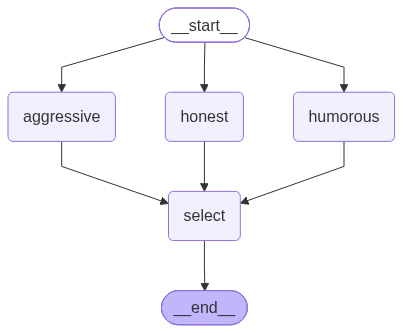

In [17]:
display(Image(simple_graph.get_graph().draw_mermaid_png()))

In [18]:
print(simple_graph.get_graph().draw_mermaid())

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	honest(honest)
	humorous(humorous)
	aggressive(aggressive)
	select(select)
	__end__([<p>__end__</p>]):::last
	__start__ --> aggressive;
	__start__ --> honest;
	__start__ --> humorous;
	aggressive --> select;
	honest --> select;
	humorous --> select;
	select --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



위 글자는 [Mermaid](https://mermaid.live) 문법입니다. 그대로 붙여 넣으면 그림이 나옵니다.

`__start__`에서 화살표 세 개가 갈라져 나가고 `select`에서 다시 모이는 것이 보입니다.
**엣지를 그은 대로 그림이 나옵니다.** 코드와 그림이 어긋날 수 없습니다.

## Step 5. 실행하고 단계별로 들여다보기

`.invoke()`는 최종 상태만 줍니다.
`.stream(stream_mode="updates")`는 **노드가 끝날 때마다 무엇이 바뀌었는지** 알려 줍니다.

디버깅할 때 이쪽이 훨씬 유용합니다. 어느 노드에서 값이 이상해졌는지 바로 보입니다.

In [10]:
state = new_state("영업 메일 초안을 하나 써 주세요")

for step in simple_graph.stream(state, stream_mode="updates"):
    for node_name, changed in step.items():
        keys = list(changed.keys())
        print(f"[{node_name:11}] 바뀐 칸: {keys}")
        if "drafts" in changed:
            print("              ", changed["drafts"][0].splitlines()[0])

[honest     ] 바뀐 칸: ['drafts']
               [판매원1 (정직)]


[humorous   ] 바뀐 칸: ['drafts']
               [판매원2 (유머)]


[aggressive ] 바뀐 칸: ['drafts']
               [판매원3 (공격)]


[select     ] 바뀐 칸: ['selected']


In [11]:
final = simple_graph.invoke(new_state("영업 메일 초안을 하나 써 주세요"))

print("모인 초안 수:", len(final["drafts"]))
print("고른 메일 첫 줄:", final["selected"].splitlines()[0])
print()
print(final["selected"][:400])

모인 초안 수: 3
고른 메일 첫 줄: 안녕하세요.  

안녕하세요.  
주식회사 윈스테크넷 영업 담당자입니다.

저희는 네트워크 단에서 알려지지 않은 악성코드와 표적 공격을 탐지하고 차단하는 APT 대응 솔루션 **스나이퍼 APT**를 제공하고 있습니다.

스나이퍼 APT는 네트워크를 통과하는 트래픽을 분석해, 기존에 알려진 패턴뿐 아니라 의심스러운 행위도 함께 확인하는 방식으로 위협 대응을 지원합니다.  
다만, 모든 공격을 100% 차단하거나 모든 내부 단말의 문제를 직접 해결하는 제품은 아닙니다. 또한 단말 내부에서 이미 실행된 행위나, 네트워크를 거치지 않는 일부 공격은 탐지 범위에 한계가 있을 수 있습니다.

고객 환경에 따라 도입 방식과 기대 효과가 달라질 수 있어, 현재 운영 중인 보안 체계와 함께 검토하시는 것이 가장 정확합니다.  
원하시면 제품


## Step 6. 검수 노드 — 고리를 만들 준비

이제 LangGraph만 할 수 있는 것을 만듭니다. **검수에서 떨어지면 다시 쓰게** 합니다.

검수는 **LLM이 아니라 규칙**으로 합니다. 이유가 있습니다.

| | LLM 검수 | 규칙 검수 |
|---|---|---|
| 같은 입력 → 같은 결과 | 보장 안 됨 | **보장됨** |
| 비용 | API 호출 | 없음 |
| 왜 걸렸는지 | 설명이 매번 다름 | **어느 낱말인지 정확히** |

회사 메일 가이드처럼 **명확히 적을 수 있는 규칙**은 LLM에게 맡길 이유가 없습니다.
판단이 필요한 일만 LLM에게 주세요. 이 원칙은 프레임워크와 무관합니다.

In [12]:
# 회사 메일 가이드가 금지하는 표현이라고 하자.
BANNED = ["망합니다", "망할", "무너집니다", "무너질", "100%", "절대",
          "반드시 지금", "당장", "폐업", "치명적"]

MAX_LENGTH = 1200


def review_node(state: State) -> dict:
    """규칙으로 검수한다. 걸린 표현을 issues에 담는다."""
    text = state["selected"]
    found = [w for w in BANNED if w in text]
    if len(text) > MAX_LENGTH:
        found.append(f"길이초과({len(text)}자)")
    return {"issues": found}


# 규칙이 실제로 잡는지 확인한다.
demo = {"selected": "지금 도입하지 않으면 귀사는 망합니다. 100% 보장합니다."}
print("걸린 항목:", review_node(demo)["issues"])

걸린 항목: ['망합니다', '100%']


## Step 7. 조건부 엣지 — 갈림길과 되돌아가는 고리

```python
graph.add_conditional_edges("review", route, {"send": "send", "revise": "revise"})
```

`route`는 **다음에 갈 노드 이름을 문자열로 돌려주는 함수**입니다.
평범한 파이썬 함수라 원하는 조건을 마음대로 쓸 수 있습니다.

### 무한 루프를 막아야 합니다

고리를 만들면 **영원히 돌 수 있습니다.** 재작성해도 계속 걸리면 끝나지 않습니다.
그래서 `revisions` 칸으로 횟수를 세고, 한도를 넘으면 포기합니다.

**고리를 만들 때는 반드시 탈출 조건을 함께 만드세요.** 그래프에서 가장 흔한 사고입니다.
(LangGraph에도 `recursion_limit` 기본값이 있지만, 그것은 예외를 던질 뿐
 우리가 원하는 방식으로 마무리해 주지는 않습니다.)

In [13]:
MAX_REVISIONS = 2


def revise_node(state: State) -> dict:
    """걸린 표현을 빼고 다시 쓰게 한다."""
    fix_prompt = ChatPromptTemplate.from_messages([
        ("system",
         "당신은 영업 메일을 회사 가이드에 맞게 고칩니다.\n"
         "다음 표현은 금지되어 있습니다: {issues}\n"
         "이 표현들을 빼고, 위협하거나 압박하지 않는 차분한 표현으로 바꾸세요.\n"
         "메일의 핵심 내용은 유지하고, **첫 줄의 '제목:' 줄도 반드시 유지**하세요.\n"
         "고친 메일 전문만 출력하세요."),
        ("human", "{email}"),
    ])
    fixed = (fix_prompt | llm | parser).invoke(
        {"issues": ", ".join(state["issues"]), "email": state["selected"]})
    return {"selected": fixed, "revisions": state["revisions"] + 1}


def split_subject(text: str) -> tuple[str, str]:
    """'제목:'으로 시작하는 줄을 찾아 제목과 본문으로 나눈다.

    첫 줄을 무조건 제목으로 쓰지 않는 이유 — 실제로 겪은 문제:
      재작성 노드를 거치면 모델이 '제목:' 줄을 빼먹는 일이 있다.
      그때 첫 줄을 제목으로 삼으면 메일 제목이 "안녕하세요."가 되어 버린다.
      **LLM이 형식을 지킬 것이라고 가정하지 마세요.** 지시해도 가끔 어깁니다.
    """
    lines = text.splitlines()
    for i, line in enumerate(lines):
        if line.strip().startswith("제목:"):
            subject = line.split("제목:", 1)[1].strip()
            body = "\n".join(lines[i + 1:]).strip()
            return subject, body
    return "(제목 없음) 스나이퍼 APT 안내", text.strip()


def send_node(state: State) -> dict:
    """제목과 본문을 나눠 발송한다."""
    subject, body = split_subject(state["selected"])
    return {"sent": send_message(subject, body)}


def give_up_node(state: State) -> dict:
    """한도를 넘었다. 보내지 않고 사람에게 넘긴다."""
    print(f"[중단] {state['revisions']}번 고쳤지만 여전히 걸립니다: {state['issues']}")
    print("      사람이 직접 검토해야 합니다.")
    return {"sent": "발송하지 않음 (검수 미통과)"}


def route(state: State) -> Literal["send", "revise", "give_up"]:
    """검수 결과를 보고 다음 노드를 정한다."""
    if not state["issues"]:
        return "send"
    if state["revisions"] >= MAX_REVISIONS:
        return "give_up"
    return "revise"


print("검수 / 재작성 / 발송 / 포기 노드 준비 완료")

검수 / 재작성 / 발송 / 포기 노드 준비 완료


### 그래프에 고리를 넣습니다

핵심은 이 한 줄입니다.

```python
builder.add_edge("revise", "review")     # 되돌아간다
```

`revise`에서 `review`로 화살표를 그으면 고리가 완성됩니다.
LangChain의 `|`로는 쓸 수 없는 모양입니다.

In [14]:
builder2 = StateGraph(State)
for key in STYLES:
    builder2.add_node(key, make_writer(key))
builder2.add_node("select", select_node)
builder2.add_node("review", review_node)
builder2.add_node("revise", revise_node)
builder2.add_node("send", send_node)
builder2.add_node("give_up", give_up_node)

for key in STYLES:
    builder2.add_edge(START, key)
    builder2.add_edge(key, "select")

builder2.add_edge("select", "review")
builder2.add_conditional_edges("review", route,
                               {"send": "send", "revise": "revise", "give_up": "give_up"})
builder2.add_edge("revise", "review")      # <-- 되돌아가는 고리
builder2.add_edge("send", END)
builder2.add_edge("give_up", END)

graph = builder2.compile()
print(graph.get_graph().draw_mermaid())

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	honest(honest)
	humorous(humorous)
	aggressive(aggressive)
	select(select)
	review(review)
	revise(revise)
	send(send)
	give_up(give_up)
	__end__([<p>__end__</p>]):::last
	__start__ --> aggressive;
	__start__ --> honest;
	__start__ --> humorous;
	aggressive --> select;
	honest --> select;
	humorous --> select;
	review -.-> give_up;
	review -.-> revise;
	review -.-> send;
	revise --> review;
	select --> review;
	give_up --> __end__;
	send --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



`review -.-> revise` 와 `revise --> review` 두 화살표가 **서로를 가리키는 것**이 보입니다.
점선(`-.->`)은 조건부 엣지입니다.

In [15]:
print("실행 시작\n")
for step in graph.stream(new_state("영업 메일 초안을 하나 써 주세요"),
                         stream_mode="updates"):
    for node_name, changed in step.items():
        note = ""
        if node_name == "review":
            note = f"걸린 항목 {changed['issues'] or '없음'}"
        elif node_name == "revise":
            note = f"재작성 {changed['revisions']}회차"
        print(f"[{node_name:9}] {note}")

실행 시작



[honest   ] 


[humorous ] 


[aggressive] 


[select   ] 
[review   ] 걸린 항목 ['100%']


[revise   ] 재작성 1회차
[review   ] 걸린 항목 없음
[미리보기] 실제로 보내지 않았습니다
제목: 스나이퍼 APT 안내 및 검토 제안
------------------------------------------------------------------
안녕하세요.  
주식회사 윈스테크넷의 영업 담당자입니다.

당사는 **스나이퍼 APT**라는 지능형 지속 위협(APT) 대응 솔루션을 제공하고 있습니다.  
이 솔루션은 **네트워크 구간에서 알려지지 않은 악성코드 및 표적 공격의 징후를 탐지하고 차단하는 데** 활용하실 수 있습니다.

스나이퍼 APT는 기존의 단순 시그니처 기반 탐지로는 확인이 어려운 위협을 보완하는 용도로 검토하실 수 있습니다.  
또한 네트워크를 통과하지 않는 위협이나 단말 내부에서만 발생하는 문제는 별도의 대응이 필요할 수 있습니다.

관심 있으시면 제품 기능, 적용 방식, 도입 절차를 간단히 설명드리겠습니다.  
가능하신 일정이 있으면 회신 부탁드립니다.

감사합니다.  
주식회사 윈스테크넷  
영업 담당자 드림
[send     ] 


위 출력에서 **`review`가 두 번 나타났다면 고리가 돈 것입니다.**
검수에 걸린 표현이 있어 `revise`로 갔다가, 다시 `review`로 돌아왔다는 뜻입니다.

실행할 때마다 다릅니다. 선택자가 정직한 메일을 고르면 한 번에 통과하기도 합니다.

### 고리를 확실히 보고 싶다면

일부러 걸리는 메일을 넣으면 됩니다. 다만 위 그래프는 `START`부터 시작해서
`select`가 우리 메일을 덮어씁니다. 그래서 **검수부터 시작하는 작은 그래프**를 따로 만듭니다.

> 이것도 그래프의 장점입니다. **노드는 그냥 함수**라서, 같은 노드들을 다르게 이어
> 붙이기만 하면 됩니다. 노드를 고칠 필요가 없습니다.

In [16]:
# 같은 노드들로 검수 -> 재작성 고리만 떼어낸 작은 그래프
checker = StateGraph(State)
checker.add_node("review", review_node)
checker.add_node("revise", revise_node)
checker.add_node("send", send_node)
checker.add_node("give_up", give_up_node)

checker.add_edge(START, "review")          # 검수가 진입점
checker.add_conditional_edges("review", route,
                              {"send": "send", "revise": "revise", "give_up": "give_up"})
checker.add_edge("revise", "review")
checker.add_edge("send", END)
checker.add_edge("give_up", END)
check_graph = checker.compile()

bad_email = """제목: 지금 결정하지 않으면 늦습니다

안녕하세요.
지금 스나이퍼 APT를 도입하지 않으면 귀사는 망할 수 있습니다.
공격을 당하면 사업이 무너집니다. 저희 제품은 100% 방어를 보장합니다.
당장 회신 주십시오."""

state = new_state("(이미 작성된 메일 검수)")
state["selected"] = bad_email

print("검수 고리만 실행\n")
for step in check_graph.stream(state, stream_mode="updates"):
    for node_name, changed in step.items():
        if node_name == "review":
            print(f"[review ] 걸린 항목: {changed['issues']}")
        elif node_name == "revise":
            print(f"[revise ] {changed['revisions']}회차 재작성 -> "
                  f"{changed['selected'].splitlines()[0][:40]}")
        elif node_name in ("send", "give_up"):
            print(f"[{node_name:8}] {changed['sent']}")

검수 고리만 실행

[review ] 걸린 항목: ['망할', '무너집니다', '100%', '당장']


[revise ] 1회차 재작성 -> 제목: 지금 결정하지 않으면 늦습니다
[review ] 걸린 항목: []
[미리보기] 실제로 보내지 않았습니다
제목: 지금 결정하지 않으면 늦습니다
------------------------------------------------------------------
안녕하세요.
스나이퍼 APT 도입을 검토해 보시면 도움이 될 수 있습니다.
공격에 대비한 보안 체계를 미리 준비해 두시면 사업 운영의 안정성에 보탬이 됩니다. 저희 제품은 높은 수준의 방어를 지원합니다.
검토 가능하실 때 회신 부탁드립니다.
[send    ] 미리보기로 출력했습니다.


**`review`가 두 번 나타난 것**이 고리가 돈 증거입니다.
금지 표현 네 개가 걸렸고, 재작성 뒤 다시 검수를 받아 통과했습니다.

### 저장된 출력을 자세히 보세요 — 규칙 검수의 한계

재작성된 메일의 제목이 여전히 **"지금 결정하지 않으면 늦습니다"** 입니다.
압박하는 문구인데 통과했습니다. `BANNED` 목록에 없기 때문입니다.

**규칙 검수는 여러분이 적어 둔 것만 잡습니다.** 이것은 버그가 아니라 성질입니다.

| | 규칙 검수 | LLM 검수 |
|---|---|---|
| 적어 둔 것 | 100% 잡음 | 놓칠 수 있음 |
| 적지 않은 것 | **못 잡음** | 잡을 수도 있음 |
| 결과 재현 | 항상 같음 | 매번 다름 |

실무에서는 **둘을 겹쳐 씁니다.** 규칙으로 확실한 것을 먼저 걸러 내고,
남은 것을 LLM에게 판단하게 합니다. 그래프에서는 `review` 노드를 둘로 나누고
엣지로 이으면 됩니다. **노드를 추가하는 비용이 낮다는 것**이 그래프의 장점입니다.

**`review`가 두 번 이상 나타난 것**을 보세요. 고리가 돈 증거입니다.
재작성된 메일이 다시 검수를 받았고, 통과해서 발송으로 넘어갔습니다.

노드를 재사용해 **작은 그래프를 따로 만든 점**도 눈여겨보세요.
노드는 그냥 함수라서 이렇게 조합을 바꿔 가며 쓸 수 있습니다.

## Step 8. 체크포인터 — 상태를 저장하고 이어가기

`MemorySaver`를 붙이면 **각 단계의 상태가 저장됩니다.**

```python
graph = builder.compile(checkpointer=MemorySaver())
graph.invoke(state, {"configurable": {"thread_id": "고객사-A"}})
```

`thread_id`로 대화(작업)를 구분합니다. 같은 id로 다시 부르면 **이어서** 진행합니다.

이것이 앞의 두 프레임워크에는 없던 기능입니다.

| 쓰임새 | 설명 |
|---|---|
| 대화 이어가기 | 여러 턴에 걸친 작업의 상태 유지 |
| 중단 후 재개 | 오류가 나도 처음부터 다시 안 해도 됨 |
| 사람이 끼어들기 | 중간에 멈추고 사람이 승인한 뒤 계속 |
| 되짚어 보기 | 어느 단계의 상태든 꺼내 볼 수 있음 |

`MemorySaver`는 **메모리에만** 저장합니다. 커널을 다시 시작하면 사라집니다.
실제 서비스에서는 SQLite나 Postgres 체크포인터를 씁니다.

In [17]:
memory_graph = builder2.compile(checkpointer=MemorySaver())
config = {"configurable": {"thread_id": "고객사-A"}}

result = memory_graph.invoke(new_state("영업 메일 초안을 하나 써 주세요"), config)
print("발송 결과:", result["sent"])

[미리보기] 실제로 보내지 않았습니다
제목: (제목 없음) 스나이퍼 APT 안내
------------------------------------------------------------------
안녕하세요, 담당자님.

주식회사 윈스테크넷의 **스나이퍼 APT**를 소개드리고자 메일드립니다.  
요즘 공격자들은 정문으로만 들어오지 않더군요. 마치 “나 왔어요” 하고 인사라도 할 줄 알았는데, 조용히 숨어 들어와 오래 머무는 경우가 많습니다.

**스나이퍼 APT**는 이런 **지능형 지속 위협(APT)** 대응을 위해 설계된 솔루션으로,  
**알려지지 않은 악성코드와 표적 공격을 네트워크 단에서 탐지하고 차단**합니다.  
즉, 이상한 움직임이 보이면 “잠깐만요, 어디 가시려고요?” 하고 먼저 확인하는 든든한 보안 파수꾼입니다.

특히 다음과 같은 상황에 도움이 될 수 있습니다.

- 알려지지 않은 위협의 조기 탐지
- 표적 공격 대응 강화
- 네트워크 구간에서의 선제적 차단
- 보안 운영 부담 
발송 결과: 미리보기로 출력했습니다.


In [18]:
# 저장된 상태를 꺼내 본다.
snapshot = memory_graph.get_state(config)

print("현재 상태의 칸들:")
for key, value in snapshot.values.items():
    shown = value if isinstance(value, (int, list)) else str(value)[:50].replace("\n", " ")
    if key == "drafts":
        shown = f"{len(value)}개"
    print(f"  {key:10} = {shown}")
print()
print("다음에 실행될 노드:", snapshot.next or "(없음 — 끝까지 실행됨)")

현재 상태의 칸들:
  request    = 영업 메일 초안을 하나 써 주세요
  drafts     = 3개
  selected   = 안녕하세요, 담당자님.  주식회사 윈스테크넷의 **스나이퍼 APT**를 소개드리고자 메일드
  issues     = []
  revisions  = 0
  sent       = 미리보기로 출력했습니다.

다음에 실행될 노드: (없음 — 끝까지 실행됨)


In [19]:
# 지나온 단계들을 되짚어 본다.
history = list(memory_graph.get_state_history(config))
print(f"기록된 단계 수: {len(history)}\n")
print(f"  {'step':>5}  {'source':8} {'다음에 실행될 노드'}")
for snap in reversed(history):
    nxt = ", ".join(snap.next) if snap.next else "END"
    print(f"  {snap.metadata['step']:>5}  {snap.metadata['source']:8} {nxt}")

기록된 단계 수: 6

   step  source   다음에 실행될 노드
     -1  input    __start__
      0  loop     honest, humorous, aggressive
      1  loop     select
      2  loop     review
      3  loop     send
      4  loop     END


## Step 9. 정리 — 세 프레임워크 비교

같은 시나리오를 세 가지로 만들어 봤습니다.

| | OpenAI Agents SDK | LangChain | LangGraph |
|---|---|---|---|
| 기본 단위 | `Agent` | `Runnable` | **노드(함수) + 상태** |
| 엮는 법 | 도구 / 핸드오프 | `\|` 연산자 | 엣지 |
| 병렬 | `asyncio.gather` | `RunnableParallel` | START에서 엣지 여러 개 |
| 갈림길 | LLM이 판단 | 어려움 | `add_conditional_edges` |
| **되돌아가기** | LLM이 알아서 | **불가** | **엣지 한 줄** |
| 중간 상태 | SDK 내부 | 직접 관리 | **State** |
| 중단/재개 | 없음 | 없음 | **체크포인터** |
| 흐름 그림 | 없음 | 없음 | **`draw_mermaid()`** |
| 코드 양 | 적음 | 보통 | **많음** |

### 고르는 기준

- **흐름이 일직선** → LangChain. 그래프는 과합니다.
- **모델이 알아서 판단하게** → OpenAI Agents SDK. 코드가 가장 적습니다.
- **되돌아가는 고리가 있다** → LangGraph. 다른 선택지가 없습니다.
- **중간에 사람이 승인해야 한다** → LangGraph. 체크포인터가 필요합니다.
- **흐름을 그림으로 보여줘야 한다** → LangGraph.

> **LangGraph는 코드가 가장 깁니다.** 그 대가로 **흐름이 명시적**입니다.
> 어떤 노드가 어떤 조건에서 어디로 가는지 전부 코드에 적혀 있고, 그림으로 확인됩니다.
> 흐름이 복잡할수록 이 쪽이 유리하고, 단순할 때는 그냥 번거롭습니다.

### 이 노트북에서 기억할 것

| | |
|---|---|
| 노드는 그냥 함수 | 상태를 받고 바꿀 칸만 돌려줍니다 |
| 리듀서는 동시에 쓰는 칸에만 | 없으면 `InvalidUpdateError`로 **멈춥니다** |
| 병렬 = 엣지 여러 개 | 특별한 문법이 없습니다 |
| 고리에는 탈출 조건을 | `revisions` 같은 카운터가 필요합니다 |
| 규칙으로 될 일은 규칙으로 | 검수를 LLM에게 맡길 이유가 없었습니다 |
| 그래프는 그림으로 확인 | `draw_mermaid()` — 코드와 어긋날 수 없습니다 |

### 더 해볼 것

1. `BANNED`에 낱말을 더 넣고 재작성이 몇 번 도는지 보세요.
2. `MAX_REVISIONS`를 0으로 바꾸면 바로 `give_up`으로 가는지 확인해 보세요.
3. `send` 앞에 사람 승인 노드를 넣어 보세요 (`interrupt_before=["send"]`).
4. 판매원을 한 명 더 추가해 보세요. `STYLES`에 한 항목만 넣으면 됩니다.